In [1]:
from pathlib import Path
import os
import sys

_repo_root = Path.cwd().resolve()
if _repo_root.name == "notebooks":
    _repo_root = _repo_root.parent
if not (_repo_root / "src" / "data.py").is_file():
    raise RuntimeError("Launch this notebook from the repository root or its notebooks/ folder.")
os.chdir(_repo_root)
if str(_repo_root) not in sys.path:
    sys.path.insert(0, str(_repo_root))


# 04. Summary: the simple-to-complex ladder across both tasks

**Purpose.** Collect the results of notebooks 02 (classification) and 03 (regression) in one place. This notebook reads only the exported tables and `run_metadata.json` files, so it refits nothing and runs in seconds. It draws the cross-task ladder figures, writes `RESULTS_SUMMARY.md` for the report, and merges both tasks' metadata. All logic lives in `src/summary.py`, which also runs as `python -m src.summary`. The models were chosen in notebooks 02 and 03 on Validation alone (day-level bootstrap against the Validation leader; the simplest model retained by the comparison heuristic wins): **C2B · Logistic (BIC)** for classification and **R2B · OLS (BIC)** for regression. CV only tunes and selects features within a family, and June is excluded from the revised selection rule. Every rung is shown on CV, Validation and Test (June), with July and August as Monitoring. Canceled and unavailable orders are excluded from both tasks.

**Assessment scope.** June was examined in the original submission. The revised selection rule uses Train/CV and Validation without June scores, but this is a retrospective reanalysis, not a newly untouched test. Intervals that include zero indicate uncertainty; they do not prove equivalence.

**Contents**
1. Setup and load
2. Model key (codes, short labels, descriptions, feature counts)
3. The ladder: baseline, linear (all), linear (selected), single tree, Random Forest (default), Random Forest (tuned)
4. Overfitting gaps (Train minus CV)
5. Drift from June to August
6. Write `RESULTS_SUMMARY.md` and the merged `run_metadata.json`

## 1. Setup and load

Load both tasks' exports. `ROOT` is the folder the notebooks wrote to.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from src import summary as sm

ROOT = Path('results/simple_to_complex')
FIG = ROOT / 'figures'
tasks = [sm.load_task(name, ROOT) for name in sm.TASKS]

## 2. Model key

Codes (C0 to C4 and C3d, R0a to R4 and R3d) are the stable keys in every export; tables and figures show the short label next to them. Features is the number of raw features each model uses, read from the tasks' `run_metadata.json`. The labels live in `src/model_labels.py`.

In [3]:
display(Markdown('\n'.join(sm.model_key_markdown(tasks))))

**Classification: will the order arrive late?**

| Code | Model | Description | Features |
|---|---|---|---|
| C0 | No-skill baseline | Predicts the Train late rate for every order | - |
| C1 | Logistic (all) | Plain logistic regression, all 24 features, pre-specified transforms | 24 |
| C2 | Logistic (CV-stepwise) | Plain logistic, features chosen by CV forward stepwise with the 1-SE rule | 1 |
| C2B | Logistic (BIC) | Plain logistic, features chosen by BIC forward stepwise | 13 |
| C4 | Decision tree (tuned) | Single decision tree, raw 24 features, depth, leaf size and split rule tuned by CV grid search | 24 |
| C3 | Random Forest (tuned) | Random Forest, raw 24 features, hyperparameters tuned by two-stage CV search | 24 |
| C3d | Random Forest (default) | Random Forest, raw 24 features, scikit-learn default hyperparameters | 24 |

**Regression: days from the promised delivery date**

| Code | Model | Description | Features |
|---|---|---|---|
| R0a | Median baseline | Predicts the Train median days from promise for every order | - |
| R0b | Olist promise | Predicts arrival exactly on the promised date (0 days), with the lead time capped at 45 days | - |
| R1 | OLS (all) | Ordinary least squares, all 24 features, pre-specified transforms | 24 |
| R2 | OLS (CV-stepwise) | OLS, features chosen by CV forward stepwise with the 1-SE rule | 1 |
| R2B | OLS (BIC) | OLS, features chosen by BIC forward stepwise | 17 |
| R4 | Decision tree (tuned) | Single decision tree, raw 24 features, depth and leaf size tuned by CV grid search on RMSE | 24 |
| R3 | Random Forest (tuned) | Random Forest, raw 24 features, hyperparameters tuned by two-stage CV search on RMSE | 24 |
| R3d | Random Forest (default) | Random Forest, raw 24 features, scikit-learn default hyperparameters | 24 |


## 3. The ladder

Each rung adds complexity: no-skill or median baseline, plain linear model on all 24 features, linear model on the CV-stepwise subset, tuned single decision tree, default Random Forest, tuned Random Forest. The ladder shows the CV-stepwise subset (C2, R2) as the selected-linear rung; the models actually selected on Validation (C2B, R2B) are listed in `RESULTS_SUMMARY.md`. The primary metric is AP (higher is better) for classification and RMSE in days (lower is better) for regression.

**Classification: will the order arrive late?** (Average precision (AP, %))

| Rung | Code | Model | CV mean +/- SD | Validation | Test (June) |
|---|---|---|---|---|---|
| Baseline | C0 | No-skill baseline | 8.37 +/- 3.51 | 10.06 | 1.89 |
| Linear, all | C1 | Logistic (all) | 11.75 +/- 2.89 | 24.63 | 7.67 |
| Linear, selected | C2 | Logistic (CV-stepwise) | 12.42 +/- 4.21 | 17.36 | 3.36 |
| Single tree | C4 | Decision tree (tuned) | 10.79 +/- 3.94 | 16.76 | 3.33 |
| RF, default | C3d | Random Forest (default) | 11.79 +/- 4.68 | 18.36 | 5.24 |
| RF, tuned | C3 | Random Forest (tuned) | 12.98 +/- 5.06 | 20.66 | 9.48 |

**Regression: days from the promised delivery date** (RMSE (days))

| Rung | Code | Model | CV mean +/- SD | Validation | Test (June) |
|---|---|---|---|---|---|
| Baseline | R0a | Median baseline | 9.27 +/- 1.02 | 9.86 | 11.69 |
| Linear, all | R1 | OLS (all) | 8.65 +/- 1.35 | 8.21 | 7.37 |
| Linear, selected | R2 | OLS (CV-stepwise) | 8.61 +/- 1.16 | 8.93 | 9.37 |
| Single tree | R4 | Decision tree (tuned) | 8.65 +/- 1.11 | 9.01 | 9.60 |
| RF, default | R3d | Random Forest (default) | 8.71 +/- 1.01 | 8.56 | 8.39 |
| RF, tuned | R3 | Random Forest (tuned) | 8.31 +/- 0.93 | 8.40 | 7.95 |

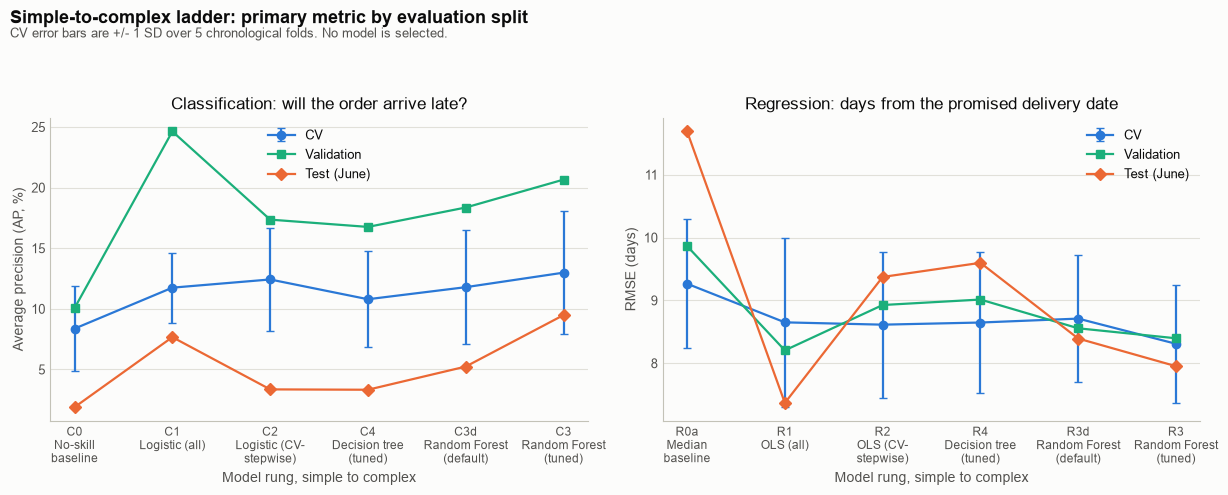

In [4]:
for task in tasks:
    display(Markdown(f'**{task.spec.title}** ({task.spec.metric_label})\n\n' + sm.ladder_markdown_table(task)))
sm.plot_ladder(tasks, FIG / '04_ladder.png')
plt.show()

## 4. Overfitting gaps

Train minus CV mean for the primary metric. A large gap means the model fits Train much better than later folds, as the default forests do.

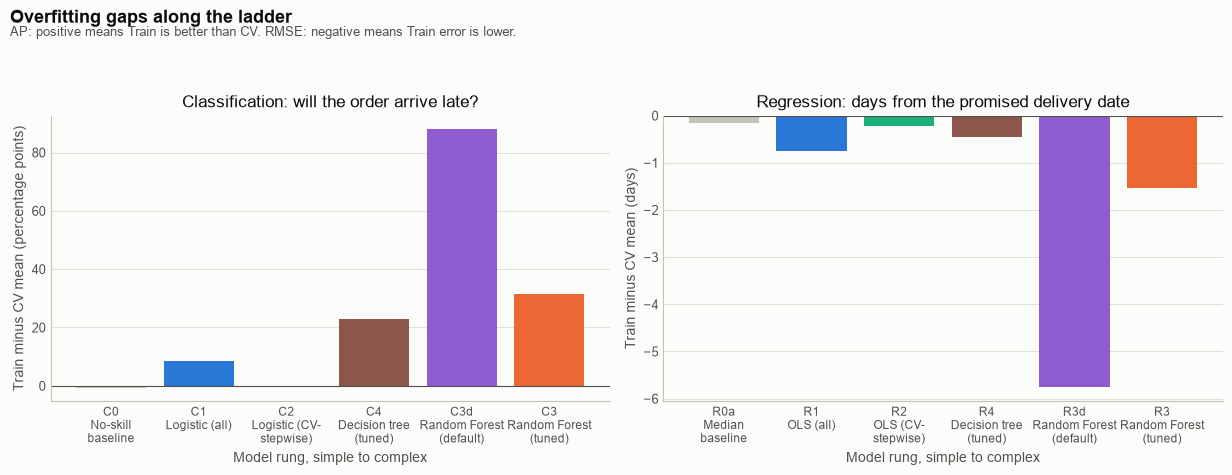

In [5]:
sm.plot_overfitting_gaps(tasks, FIG / '04_overfitting_gaps.png')
plt.show()

## 5. Drift from June to August

Frozen June models are scored on July and August without refitting. The top row shows the primary metric by month; the bottom row shows the change from June to August. Late rates differ by month, so the baselines move too.

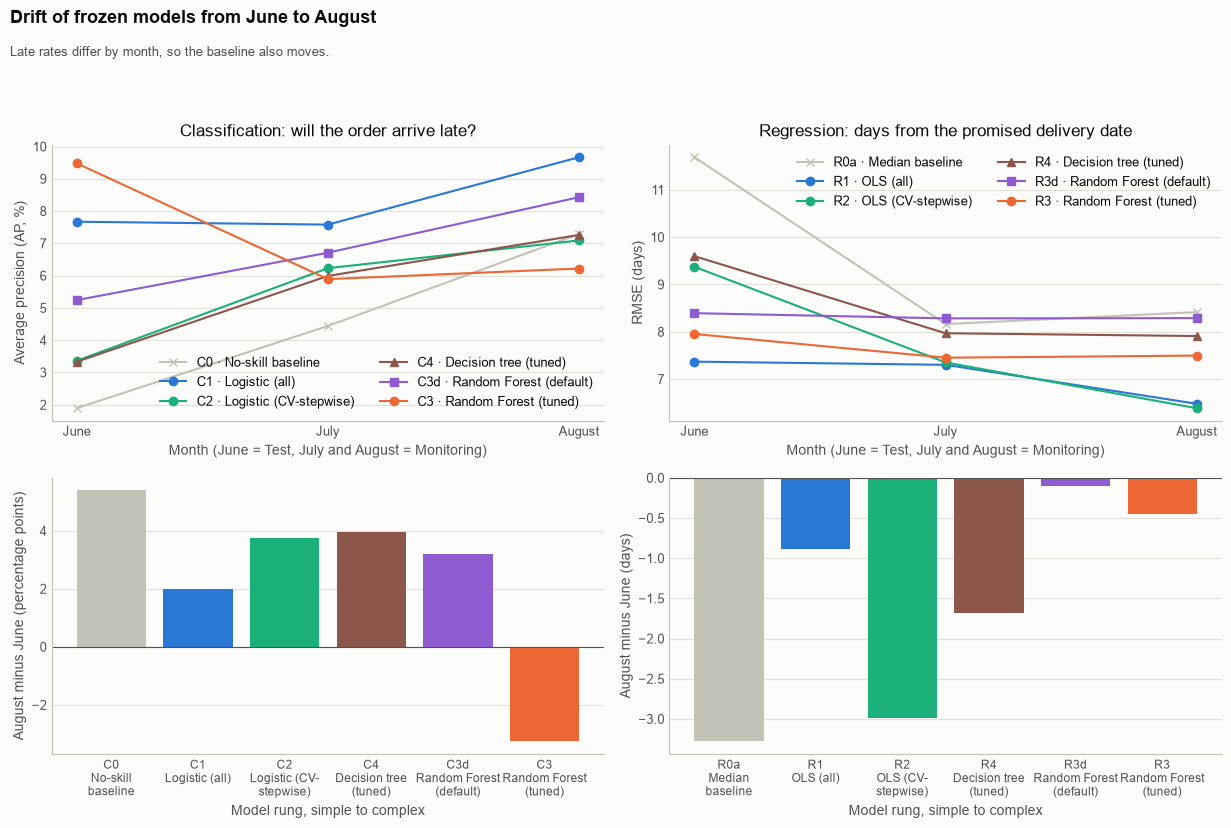

In [6]:
sm.plot_drift_summary(tasks, FIG / '04_drift_summary.png')
plt.show()

## 6. Write the summary and merged metadata

`build_summary` regenerates the three figures above, writes `RESULTS_SUMMARY.md` (every number is read from the exports) and writes `run_metadata.json` with both tasks and the package versions.

In [7]:
paths = sm.build_summary(ROOT)
for key, path in paths.items():
    print(f'{key}: {path}')
print(sm.merge_metadata(tasks)['package_versions'])

ladder: results/simple_to_complex/figures/04_ladder.png
gaps: results/simple_to_complex/figures/04_overfitting_gaps.png
drift: results/simple_to_complex/figures/04_drift_summary.png
summary: results/simple_to_complex/RESULTS_SUMMARY.md
metadata: results/simple_to_complex/run_metadata.json
{'python': '3.13.5', 'scikit-learn': '1.9.1', 'numpy': '2.5.3', 'pandas': '3.0.6', 'statsmodels': '0.15.0', 'imbalanced-learn': '0.14.2'}
